In [1]:
# ========================================
# F1 PREDICTOR V4 - MASTER NOTEBOOK
# Goal: P(podium) per driver after qualifying, judged by Brier vs E1 grid-slot baseline
# ========================================

import os
from pathlib import Path

PROJECT_DIR = Path.cwd()
os.environ['MPLCONFIGDIR'] = str(PROJECT_DIR / '.runtime' / 'matplotlib')

import sys
import platform
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import requests
import pyarrow
import sklearn
import catboost
import xgboost as xgb
import matplotlib
import matplotlib.pyplot as plt

# Project modules (code lives here, cells only call functions)
%load_ext autoreload
%autoreload 2
import data
import features
import models
import evalkit

# ========================================
# CONFIG (the one place for settings)
# ========================================

CONFIG = {
    'seasons': list(range(2022, 2027)),     # 2022 to 2026
    'seed': 42,
    'holdout_size': 10,                     # last 10 completed races
    'holdout_default': (2026, 8, 2026, 17), # (season, round) from/to, confirm in Phase 2
    'paths': {
        'raw': PROJECT_DIR / 'data' / 'raw',
        'snapshots': PROJECT_DIR / 'data' / 'snapshots',
        'models': PROJECT_DIR / 'artifacts' / 'models',
        'predictions': PROJECT_DIR / 'artifacts' / 'predictions',
    },
}

np.random.seed(CONFIG['seed'])

print("✅ All imports successful!")
print(f"🐍 Python: {platform.python_version()} ({sys.executable})")

print("\n🎯 V4 Configuration:")
print(f"   Seasons: {CONFIG['seasons'][0]}-{CONFIG['seasons'][-1]}")
print(f"   Seed: {CONFIG['seed']}")
print(f"   Holdout: last {CONFIG['holdout_size']} races (default 2026 R8-R17, confirm in Phase 2)")
print("   Metric: Brier score (never accuracy)")


✅ All imports successful!
🐍 Python: 3.14.6 (/opt/anaconda3/bin/python)

🎯 V4 Configuration:
   Seasons: 2022-2026
   Seed: 42
   Holdout: last 10 races (default 2026 R8-R17, confirm in Phase 2)
   Metric: Brier score (never accuracy)


In [2]:
# ========================================
# PHASE 0: Setup Check
# Folders, library versions, requirements.txt
# ========================================

print("📁 CREATING FOLDERS\n")
for name, path in CONFIG['paths'].items():
    path.mkdir(parents=True, exist_ok=True)
    print(f"   ✅ {name:12s} {path.relative_to(PROJECT_DIR)}")

# Library versions (logged for reproducibility)
library_versions = {
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'pyarrow': pyarrow.__version__,
    'requests': requests.__version__,
    'scikit-learn': sklearn.__version__,
    'catboost': catboost.__version__,
    'xgboost': xgb.__version__,
    'matplotlib': matplotlib.__version__,
}

print("\n📦 LIBRARY VERSIONS")
for lib, version in library_versions.items():
    print(f"   {lib:14s} {version}")

# Pin resolved versions
requirements_path = PROJECT_DIR / 'requirements.txt'
requirements_path.write_text(
    f"# Resolved on Python {platform.python_version()}\n"
    + "\n".join(f"{lib}=={version}" for lib, version in library_versions.items())
    + "\n"
)
print(f"\n✅ Wrote {requirements_path.name}")

# Project module check
print("\n🧩 PROJECT MODULES")
for module in [data, features, models, evalkit]:
    print(f"   ✅ {Path(module.__file__).name}")

print("\n🏁 PHASE 0 DONE: fresh kernel imports everything without errors")


📁 CREATING FOLDERS

   ✅ raw          data/raw
   ✅ snapshots    data/snapshots
   ✅ models       artifacts/models
   ✅ predictions  artifacts/predictions

📦 LIBRARY VERSIONS
   pandas         3.1.0
   numpy          2.5.4
   pyarrow        26.0.0
   requests       2.34.2
   scikit-learn   1.9.1
   catboost       1.2.10
   xgboost        3.4.1
   matplotlib     3.11.2

✅ Wrote requirements.txt

🧩 PROJECT MODULES
   ✅ data.py
   ✅ features.py
   ✅ models.py
   ✅ evalkit.py

🏁 PHASE 0 DONE: fresh kernel imports everything without errors


In [3]:
# ========================================
# PHASE 1 | STEP 1: Collect Raw Data (2022-2026)
# Schedule, results and qualifying from Jolpica, cached per race
# ========================================

raw_data = data.collect_raw_data(CONFIG['seasons'], CONFIG['paths']['raw'])

📊 COLLECTING RAW DATA (2022-2026)
   Source: Jolpica (Ergast-compatible), cached per race in data/raw

🏎️  Season 2022: 22 on calendar | 22 completed | results 22 | qualifying 22 ✅
🏎️  Season 2023: 22 on calendar | 22 completed | results 22 | qualifying 22 ✅
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
🏎️  Season 2024: 24 on calendar | 24 completed | results 24 | qualifying 24 ✅
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   ⏳ Rate limited, waiting 5s...
   

In [4]:
# ========================================
# PHASE 1 | STEP 2: Build Entries Table
# One row per driver per race: grid, Q times, result, status, y_podium
# ========================================

races = data.parse_schedule(raw_data['schedule'])
entries = data.build_entries(raw_data, races)

print("\n📋 Sample entries (latest race):")
sample_cols = ['season', 'round', 'driver_code', 'constructor_id', 'grid', 'quali_position',
               'q1_s', 'q2_s', 'q3_s', 'position_text', 'status', 'y_podium']
print(entries[sample_cols].tail(10).to_string(index=False))

📊 BUILDING ENTRIES TABLE

✅ Results rows: 2,212
✅ Qualifying rows: 2,207

🔗 Merging on season, round, driver_id...
✅ Entries: 2,212 rows | 109 races
✅ Podium rate: 14.8%

📋 Sample entries (latest race):
 season  round driver_code constructor_id  grid  quali_position   q1_s   q2_s   q3_s position_text  status  y_podium
   2026     17         OCO           haas    12            13.0 93.803 93.323    NaN            13  Lapped         0
   2026     17         SAI       williams    13            14.0 93.774 93.526    NaN            14  Lapped         0
   2026     17         LIN             rb     9            10.0 93.288 92.498 92.781            15  Lapped         0
   2026     17         ALO   aston_martin    20            17.0 94.223    NaN    NaN            16  Lapped         0
   2026     17         PER       cadillac    17            20.0 95.123    NaN    NaN            17  Lapped         0
   2026     17         ALB       williams    16            18.0 94.289    NaN    NaN           

In [5]:
# ========================================
# PHASE 1 | STEP 3: Sanity Checks + Coverage Report
# ========================================

data_report = data.run_sanity_checks(entries, races)

🔍 SANITY CHECKS


📅 SESSION DATE CHECK (qualifying must be 0-3 days before the race)
   ✅ No flagged races

🎰 Las Vegas (known Jolpica date issue):
   2023 R21: quali 2023-11-17 08:00:00+00:00 | race 2023-11-19 06:00:00+00:00
   2024 R22: quali 2024-11-22 06:00:00+00:00 | race 2024-11-23 06:00:00+00:00
   2025 R22: quali 2025-11-22 04:00:00+00:00 | race 2025-11-23 04:00:00+00:00

📋 COVERAGE BY SEASON
        races  rows  podium_rows  no_quali_row  pit_lane  dsq  dns
season                                                            
2022       22   440           66             0        10    0    1
2023       22   440           66             0         2    2    5
2024       24   479           72             0         1    2    3
2025       24   479           72             1         0    6    3
2026       17   374           51             5         0    0    7

📊 CHECKS
   ✅ Every race has exactly 3 podium rows ([])
   ✅ No duplicate driver-race rows (0)
   ✅ About 20 drivers per race 

In [6]:
# ========================================
# PHASE 1 | STEP 4: Save Snapshot + Data Notes
# ========================================

snapshot_path, snapshot_hash = data.save_snapshot(entries, CONFIG['paths']['snapshots'])
data.write_data_notes(data_report, snapshot_path, snapshot_hash, PROJECT_DIR / 'data_notes.md')

if data_report['passed']:
    print("\n🏁 PHASE 1 DONE: 3 podium rows per race, ~20 drivers per race, gaps counted and documented")
else:
    print("\n❌ PHASE 1 NOT DONE: see failed checks above")

💾 Snapshot: entries_2026_R17_929de9087d5b.parquet
   Rows: 2,212 | Hash: 929de9087d5b
📝 Wrote data_notes.md

🏁 PHASE 1 DONE: 3 podium rows per race, ~20 drivers per race, gaps counted and documented


In [7]:
# ========================================
# PHASE 1 | STEP 5: Las Vegas Date Fix + Final Snapshot
# Jolpica had LV 2023 quali and LV 2024 quali + race one day early
# ========================================

races, entries = data.apply_date_fixes(races, entries)

print()
snapshot_path, snapshot_hash = data.save_snapshot(entries, CONFIG['paths']['snapshots'])
data.write_data_notes(data_report, snapshot_path, snapshot_hash, PROJECT_DIR / 'data_notes.md')
data.append_data_notes(PROJECT_DIR / 'data_notes.md', data.DATE_FIX_NOTE)

🔧 APPLYING KNOWN DATE FIXES

   ✅ 2023 R21 quali_datetime_utc: 2023-11-17 08:00:00+00:00 → 2023-11-18 08:00:00+00:00
   ✅ 2023 R21 race_datetime_utc: 2023-11-19 06:00:00+00:00 → 2023-11-19 06:00:00+00:00
   ✅ 2024 R22 quali_datetime_utc: 2024-11-22 06:00:00+00:00 → 2024-11-23 06:00:00+00:00
   ✅ 2024 R22 race_datetime_utc: 2024-11-23 06:00:00+00:00 → 2024-11-24 06:00:00+00:00

💾 Snapshot: entries_2026_R17_68ee1ec64f65.parquet
   Rows: 2,212 | Hash: 68ee1ec64f65
📝 Wrote data_notes.md
📝 Appended to data_notes.md


In [8]:
# ========================================
# PHASE 2 | STEP 1: Freeze Dev / Holdout Split
# Warmup = training only, Dev = scored backtest, Holdout = opened once in Phase 5
# ========================================

CONFIG['dev_start'] = (2024, 1)
CONFIG['n_boot'] = 2000

split_races, entries = evalkit.make_split(entries, CONFIG['holdout_size'], CONFIG['dev_start'])

holdout_races = split_races[split_races['role'] == 'holdout']
first, last = holdout_races.iloc[0], holdout_races.iloc[-1]
assert (first['season'], first['round'], last['season'], last['round']) == CONFIG['holdout_default']
print(f"\n✅ Holdout confirmed: {first['season']} R{first['round']} → {last['season']} R{last['round']} (plan default)")

# Everything until Phase 5 uses these two only
dev_table = entries[entries['role'] != 'holdout']
dev_races = split_races[split_races['role'] == 'dev']
print(f"✅ dev_table: {len(dev_table):,} rows (warmup + dev) | dev_races: {len(dev_races)} scored races")

🔒 DEV / HOLDOUT SPLIT (by race date)

   warmup    44 races | 2022 R1  → 2023 R22
   dev       55 races | 2024 R1  → 2026 R7 
   holdout   10 races | 2026 R8  → 2026 R17

✅ Holdout confirmed: 2026 R8 → 2026 R17 (plan default)
✅ dev_table: 1,992 rows (warmup + dev) | dev_races: 55 scored races


In [9]:
# ========================================
# PHASE 2 | STEP 2: Metric Unit Tests
# ========================================

evalkit.run_metric_tests(CONFIG['seed'])

🧪 METRIC UNIT TESTS (tiny synthetic data)

   ✅ Brier matches sklearn
   ✅ Brier: perfect = 0, coin flip = 0.25
   ✅ Log loss matches sklearn
   ✅ Race-level Brier equals row-level Brier
   ✅ Probability sums: 20 drivers x 0.15 = 3
   ✅ Calibration observed rates (0.0 and 1.0)
   ✅ Bootstrap interval contains the estimate
   ✅ Identical races → zero-width interval
   ✅ Model vs itself → difference 0 (0, 0)

✅ All 9 metric tests passed


True

In [10]:
# ========================================
# PHASE 2 | STEP 3: Backtest Baselines E0 + E1
# Expanding window, retrain before each race, predictions saved with timestamps
# ========================================

baselines = [models.DriverRateBaseline(), models.GridSlotBaseline()]

dev_predictions = {}
for model in baselines:
    dev_predictions[model.name] = evalkit.backtest(model, dev_table, dev_races,
                                                   save_dir=CONFIG['paths']['predictions'])

🏋️ BACKTEST: E0_driver_rate on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E0_driver_rate.parquet
🏋️ BACKTEST: E1_grid_slot on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_grid_slot.parquet


In [11]:
# ========================================
# PHASE 2 | STEP 4: Results Table + Calibration
# ========================================

baseline_results = evalkit.compare_models(list(dev_predictions.values()), baseline='E1_grid_slot',
                                          n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])

for name, preds in dev_predictions.items():
    print(f"\n🎯 Calibration: {name}")
    print(evalkit.calibration_table(preds).to_string(index=False))

📊 RESULTS (55 races, 95% intervals by race bootstrap)

   Model              Brier          [95% CI]  LogLoss          [95% CI]  Δ vs E1_grid_slot            [95% CI]      Σp per race
   E0_driver_rate    0.0999 [0.0916, 0.1079]   0.3805 [0.2965, 0.4981]            +0.0341 [+0.0251, +0.0431]  3.02 (2.72-3.46)
   E1_grid_slot      0.0657 [0.0583, 0.0733]   0.2189 [0.1957, 0.2445]            +0.0000 [+0.0000, +0.0000]  2.85 (2.78-2.92)

🎯 Calibration: E0_driver_rate
           bin  rows   mean_p  observed
(-0.001, 0.05]   609 0.005258  0.011494
   (0.05, 0.1]    47 0.081156  0.063830
    (0.1, 0.2]    64 0.147099  0.187500
    (0.2, 0.3]   160 0.250082  0.306250
    (0.3, 0.5]   177 0.379521  0.361582
    (0.5, 0.7]     4 0.696428  0.750000
    (0.7, 1.0]    51 0.774484  0.529412

🎯 Calibration: E1_grid_slot
           bin  rows   mean_p  observed
(-0.001, 0.05]   675 0.019358  0.010370
   (0.05, 0.1]   105 0.071193  0.038095
    (0.1, 0.2]    66 0.143078  0.106061
    (0.2, 0.3]    46 0

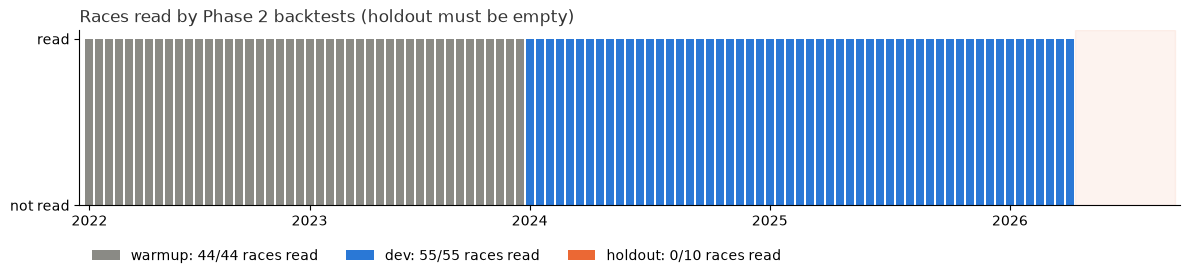

✅ Holdout races read: 0
✅ E1 dev Brier 0.0657 (plan expects ~0.068)

🏁 PHASE 2 DONE: metric tests pass, E1 reproduced, holdout never accessed
   🎯 The bar to beat: E1 dev Brier = 0.0657


In [12]:
# ========================================
# PHASE 2 | STEP 5: Holdout Access Check + Done
# ========================================

holdout_read = evalkit.plot_holdout_access(split_races, list(dev_predictions.values()),
                                           save_path=PROJECT_DIR / 'artifacts' / 'phase2_holdout_access.png')

e1_brier = baseline_results.loc[baseline_results['model'] == 'E1_grid_slot', 'brier'].iloc[0]
e1_reproduced = abs(e1_brier - 0.068) < 0.005
print(f"{'✅' if e1_reproduced else '❌'} E1 dev Brier {e1_brier:.4f} (plan expects ~0.068)")

if holdout_read == 0 and e1_reproduced:
    print("\n🏁 PHASE 2 DONE: metric tests pass, E1 reproduced, holdout never accessed")
    print(f"   🎯 The bar to beat: E1 dev Brier = {e1_brier:.4f}")
else:
    print("\n❌ PHASE 2 NOT DONE: see checks above")

In [13]:
# ========================================
# PHASE 3 | STEP 1: Build Features (13 features, 4 groups)
# One race at a time, only earlier races (sorted by date, never by driver)
# Holdout races are excluded until Phase 5
# ========================================

dev_entries = entries[entries['role'] != 'holdout']
feature_table = features.build_features(dev_entries)

print("\n📋 Sample features (2026 R7, front of the grid):")
sample = feature_table[(feature_table['season'] == 2026) & (feature_table['round'] == 7)].nsmallest(6, 'grid')
print(sample[['driver_code'] + features.FEATURE_COLUMNS].set_index('driver_code').T.round(3).to_string())

🔧 BUILDING FEATURES (13 features in 4 groups)

A_qualifying
   ✅ grid_position                 99.2% non-missing
   ✅ quali_gap_to_pole_pct         97.8% non-missing
   ✅ made_q3                       99.8% non-missing
   ✅ teammate_quali_gap_pct        96.6% non-missing
   ✅ pit_lane_flag                100.0% non-missing
   ✅ quali_missing                100.0% non-missing
B_driver_form
   ✅ driver_avg_finish_last5       98.4% non-missing
   ✅ driver_podium_rate_last10     98.4% non-missing
   ✅ driver_dnf_rate_last10        98.4% non-missing
C_team_strength
   ✅ team_avg_finish_last5         98.6% non-missing
   ✅ team_podium_rate_last5        98.6% non-missing
D_circuit_history
   ✅ driver_circuit_podium_rate    98.4% non-missing
   ✅ driver_circuit_starts        100.0% non-missing

✅ Feature table: 1,992 rows | 99 races

📋 Sample features (2026 R7, front of the grid):
driver_code                   RUS    HAM    ANT     NOR     VER     HAD
grid_position               1.000  2.000  

In [14]:
# ========================================
# PHASE 3 | STEP 2: Leak Test
# Must pass before any model is trained
# ========================================

leak_test_passed = features.run_leak_test(dev_entries, feature_table)
assert leak_test_passed, "Leak test failed: fix features before training anything"

🔒 LEAK TEST (delete later races + poison this race's outcomes)

   ✅ Features unchanged in 99/99 races
   ✅ Canary (deliberately leaky feature) caught in 99/99 races

✅ LEAK TEST PASSED


In [15]:
# ========================================
# PHASE 3 | STEP 3: Feature Ablation (one group at a time on top of E1)
# Learner: logistic regression on logit(E1) + group features (C fixed, not tuned)
# Keep rule: Δ Brier < 0 and ≥ 90% of race-bootstrap draws below zero
# ========================================

ablation, kept_groups, ablation_predictions = evalkit.run_ablation(
    make_model=lambda columns, name: models.E1PlusLogistic(columns, name),
    table=feature_table,
    eval_races=dev_races,
    groups=features.FEATURE_GROUPS,
    reference_preds=dev_predictions['E1_grid_slot'],
    n_boot=CONFIG['n_boot'],
    seed=CONFIG['seed'],
    save_dir=CONFIG['paths']['predictions'],
)

ablation.to_csv(PROJECT_DIR / 'artifacts' / 'phase3_ablation.csv', index=False)
print("\n💾 Saved artifacts/phase3_ablation.csv")

🧪 FEATURE ABLATION (forward, plan order)

🏋️ BACKTEST: E1_logistic on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_logistic.parquet
🏋️ BACKTEST: E1_A on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_A.parquet
🏋️ BACKTEST: E1_B on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_B.parquet
🏋️ BACKTEST: E1_C on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_C.parquet
🏋️ BACKTEST: E1_D on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_E1_D.parquet

📊 ABLATION TABLE (Δ Brier vs current kept model, negative = better)

   Step                     Model            #feat   Δ Brier              [95% CI] P(better)  Kept
   learner only (vs E1)     E1_logistic          1   -0.0016 [-0.0025, -0.0006]      100%     -
   + A_qualifying           E1_A                 7   +0.0006 [-0.0004, +0.0022]       22%    no
   + B_driver_form          E1_B                 4   +0.0009 [-0.0033, +0.0051]       37%    no
   + C_

In [16]:
# ========================================
# PHASE 3 | STEP 4: Kept Feature Groups + Done
# ========================================

CONFIG['kept_feature_groups'] = kept_groups
kept_features = [column for group in kept_groups for column in features.FEATURE_GROUPS[group]]

print("📋 FEATURE GROUP DECISIONS (evidence: ablation table above)\n")
for _, row in ablation.iloc[1:].iterrows():
    status = "✅ KEPT   " if row['kept'] == 'YES' else "⊗ DROPPED"
    print(f"   {status} {row['step'][2:]:20s} Δ Brier {row['diff']:+.4f} | P(better) {row['share_below_zero']:.0%}")

print(f"\n🎯 Kept features: {len(kept_features)} (+ E1 logit) → {kept_features if kept_features else 'none, E1 alone'}")

if leak_test_passed:
    print("\n🏁 PHASE 3 DONE: leak test passed, kept groups listed with evidence")
else:
    print("\n❌ PHASE 3 NOT DONE: leak test failed")

📋 FEATURE GROUP DECISIONS (evidence: ablation table above)

   ⊗ DROPPED A_qualifying         Δ Brier +0.0006 | P(better) 22%
   ⊗ DROPPED B_driver_form        Δ Brier +0.0009 | P(better) 37%
   ⊗ DROPPED C_team_strength      Δ Brier -0.0011 | P(better) 67%
   ⊗ DROPPED D_circuit_history    Δ Brier +0.0015 | P(better) 20%

🎯 Kept features: 0 (+ E1 logit) → none, E1 alone

🏁 PHASE 3 DONE: leak test passed, kept groups listed with evidence


In [17]:
# ========================================
# PHASE 4 | STEP 1: Logistic Reference + CatBoost Tuning
# Boosters get all 13 features (decision after Phase 3 kept none), NaN stays NaN
# ========================================

CONFIG['booster_features'] = features.FEATURE_COLUMNS

# Simple reference: logistic regression on the kept set (E1 logit only), from Phase 3
logistic_preds = ablation_predictions['E1_logistic']
print(f"✅ Logistic reference: E1_logistic, dev Brier "
      f"{evalkit.brier_score(logistic_preds['y_podium'], logistic_preds['p']):.4f}\n")

catboost_tuning, catboost_best, catboost_all = evalkit.tune_model(
    make_model=lambda config: models.BoosterModel('CatBoost', config, CONFIG['booster_features'], CONFIG['seed']),
    configs=models.CATBOOST_GRID,
    table=feature_table,
    eval_races=dev_races,
    save_dir=CONFIG['paths']['predictions'],
)

✅ Logistic reference: E1_logistic, dev Brier 0.0642

🏋️ BACKTEST: CatBoost_d4_lr0.03 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_CatBoost_d4_lr0.03.parquet
🏋️ BACKTEST: CatBoost_d4_lr0.1 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_CatBoost_d4_lr0.1.parquet
🏋️ BACKTEST: CatBoost_d6_lr0.03 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_CatBoost_d6_lr0.03.parquet
🏋️ BACKTEST: CatBoost_d6_lr0.1 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_CatBoost_d6_lr0.1.parquet

📊 TUNING GRID (dev Brier, lower is better)
             model  depth  learning_rate  brier
CatBoost_d4_lr0.03      4         0.0300 0.0681
CatBoost_d6_lr0.03      6         0.0300 0.0717
 CatBoost_d4_lr0.1      4         0.1000 0.0763
 CatBoost_d6_lr0.1      6         0.1000 0.0812

✅ Best config: CatBoost_d4_lr0.03


In [18]:
# ========================================
# PHASE 4 | STEP 2: XGBoost Tuning (optional second booster)
# ========================================

xgboost_tuning, xgboost_best, xgboost_all = evalkit.tune_model(
    make_model=lambda config: models.BoosterModel('XGBoost', config, CONFIG['booster_features'], CONFIG['seed']),
    configs=models.XGBOOST_GRID,
    table=feature_table,
    eval_races=dev_races,
    save_dir=CONFIG['paths']['predictions'],
)

🏋️ BACKTEST: XGBoost_d3_lr0.03 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_XGBoost_d3_lr0.03.parquet
🏋️ BACKTEST: XGBoost_d3_lr0.1 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_XGBoost_d3_lr0.1.parquet
🏋️ BACKTEST: XGBoost_d5_lr0.03 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_XGBoost_d5_lr0.03.parquet
🏋️ BACKTEST: XGBoost_d5_lr0.1 on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_XGBoost_d5_lr0.1.parquet

📊 TUNING GRID (dev Brier, lower is better)
            model  max_depth  learning_rate  brier
XGBoost_d3_lr0.03          3         0.0300 0.0712
XGBoost_d5_lr0.03          5         0.0300 0.0752
 XGBoost_d3_lr0.1          3         0.1000 0.0802
 XGBoost_d5_lr0.1          5         0.1000 0.0815

✅ Best config: XGBoost_d3_lr0.03


In [19]:
# ========================================
# PHASE 4 | STEP 3: Calibration (Platt + isotonic) on the Best Booster
# Each race is calibrated using earlier races' out-of-sample predictions only
# ========================================

best_booster = min([catboost_best, xgboost_best], key=lambda preds: evalkit.brier_score(preds['y_podium'], preds['p']))
print(f"✅ Best booster: {best_booster['model'].iloc[0]}\n")

booster_platt = evalkit.calibrate_expanding(best_booster, method='platt')
booster_isotonic = evalkit.calibrate_expanding(best_booster, method='isotonic')

✅ Best booster: CatBoost_d4_lr0.03

🎯 Calibrated CatBoost_d4_lr0.03+platt (first 10 races left uncalibrated)
🎯 Calibrated CatBoost_d4_lr0.03+isotonic (first 10 races left uncalibrated)


In [20]:
# ========================================
# PHASE 4 | STEP 4: Sum-to-3 Test
# Rescale each race's probabilities to sum to 3, does Brier improve?
# ========================================

sum3_results, sum3_predictions = evalkit.sum_to_three_test(
    [dev_predictions['E1_grid_slot'], logistic_preds, best_booster],
    n_boot=CONFIG['n_boot'], seed=CONFIG['seed'],
)

⚖️ SUM-TO-3 TEST (Δ Brier after rescaling, negative = better)

   E1_grid_slot             Σp 2.85 → 3.00 | Δ Brier -0.0008 [-0.0012, -0.0004] | P(better) 100%
   E1_logistic              Σp 3.00 → 3.00 | Δ Brier -0.0000 [-0.0000, +0.0000] | P(better) 89%
   CatBoost_d4_lr0.03       Σp 3.09 → 3.00 | Δ Brier -0.0004 [-0.0017, +0.0011] | P(better) 77%


In [21]:
# ========================================
# PHASE 4 | STEP 5: Model Comparison vs E1 + Choice
# Same 55 dev races, 95% intervals by race bootstrap
# ========================================

phase4_candidates = [dev_predictions['E1_grid_slot'], logistic_preds, catboost_best, xgboost_best,
                     booster_platt, booster_isotonic, *sum3_predictions.values()]

model_results = evalkit.compare_models(phase4_candidates, baseline='E1_grid_slot',
                                       n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])
model_results.to_csv(PROJECT_DIR / 'artifacts' / 'phase4_model_comparison.csv', index=False)

print()
chosen_model, beats_e1_on_dev = evalkit.choose_model(model_results, baseline='E1_grid_slot')
CONFIG['chosen_model'] = chosen_model

if beats_e1_on_dev:
    print(f"\n🏁 PHASE 4 DONE: chosen model = {chosen_model} (clearly beats E1 on dev)")
else:
    print(f"\n🏁 PHASE 4 DONE: nothing clearly beats E1 on dev, Phase 5 tests E1 as the honest answer")

📊 RESULTS (55 races, 95% intervals by race bootstrap)

   Model              Brier          [95% CI]  LogLoss          [95% CI]  Δ vs E1_grid_slot            [95% CI]      Σp per race
   E1_grid_slot      0.0657 [0.0583, 0.0733]   0.2189 [0.1957, 0.2445]            +0.0000 [+0.0000, +0.0000]  2.85 (2.78-2.92)
   E1_logistic       0.0642 [0.0559, 0.0726]   0.2142 [0.1877, 0.2434]            -0.0016 [-0.0025, -0.0006]  3.00 (2.98-3.04)
   CatBoost_d4_lr0.03  0.0681 [0.0591, 0.0770]   0.2193 [0.1878, 0.2547]            +0.0024 [-0.0028, +0.0075]  3.09 (2.06-4.24)
   XGBoost_d3_lr0.03  0.0712 [0.0619, 0.0801]   0.2251 [0.1945, 0.2587]            +0.0055 [-0.0000, +0.0107]  3.14 (1.18-4.57)
   CatBoost_d4_lr0.03+platt  0.0683 [0.0598, 0.0767]   0.2196 [0.1900, 0.2535]            +0.0025 [-0.0025, +0.0075]  2.92 (1.94-4.24)
   CatBoost_d4_lr0.03+isotonic  0.0698 [0.0608, 0.0785]   0.2364 [0.1967, 0.2817]            +0.0041 [-0.0012, +0.0094]  2.92 (1.88-4.24)
   E1_grid_slot+sum3  0.0649 [0.

In [22]:
# ========================================
# PHASE 5 | STEP 1: Unlock the Holdout (ONE SHOT) + Holdout Features
# The lock file records the chosen model, a different model can never be scored after this
# ========================================

holdout_lock = evalkit.unlock_holdout(PROJECT_DIR / 'artifacts' / 'holdout_lock.json',
                                      CONFIG['chosen_model'], snapshot_hash)

print()
full_feature_table = features.build_features(entries)

print()
assert features.run_leak_test(entries, full_feature_table), "Leak test failed on the full table"

🔓 HOLDOUT UNLOCKED at 2026-10-23T15:09:12.817690+00:00
   Chosen model: E1_logistic+sum3 | Snapshot: 68ee1ec64f65
   This is the one shot: no model changes after this point.

🔧 BUILDING FEATURES (13 features in 4 groups)

A_qualifying
   ✅ grid_position                 99.3% non-missing
   ✅ quali_gap_to_pole_pct         97.9% non-missing
   ✅ made_q3                       99.7% non-missing
   ✅ teammate_quali_gap_pct        96.7% non-missing
   ✅ pit_lane_flag                100.0% non-missing
   ✅ quali_missing                100.0% non-missing
B_driver_form
   ✅ driver_avg_finish_last5       98.6% non-missing
   ✅ driver_podium_rate_last10     98.6% non-missing
   ✅ driver_dnf_rate_last10        98.6% non-missing
C_team_strength
   ✅ team_avg_finish_last5         98.7% non-missing
   ✅ team_podium_rate_last5        98.7% non-missing
D_circuit_history
   ✅ driver_circuit_podium_rate    98.6% non-missing
   ✅ driver_circuit_starts        100.0% non-missing

✅ Feature table: 2,212 rows

In [23]:
# ========================================
# PHASE 5 | STEP 2: Predict the Holdout (chosen model + E1)
# Same expanding window as dev: retrain before each race on all earlier races
# ========================================

holdout_e1 = evalkit.backtest(models.GridSlotBaseline(), full_feature_table, holdout_races, allow_holdout=True)
holdout_chosen = evalkit.rescale_to_three(
    evalkit.backtest(models.E1PlusLogistic([], 'E1_logistic'), full_feature_table, holdout_races, allow_holdout=True))
assert holdout_chosen['model'].iloc[0] == CONFIG['chosen_model'], "Holdout model must be the Phase 4 choice"

print()
for preds in [holdout_e1, holdout_chosen]:
    evalkit.save_predictions(preds, CONFIG['paths']['predictions'], prefix='holdout')

print("\n⊗ V3 as shipped: not scored (needs FastF1 sessions and its 47-feature pipeline)")

🏋️ BACKTEST: E1_grid_slot on 10 races (retrain every 1)
🏋️ BACKTEST: E1_logistic on 10 races (retrain every 1)

   💾 Saved 220 predictions → holdout_E1_grid_slot.parquet
   💾 Saved 220 predictions → holdout_E1_logistic+sum3.parquet

⊗ V3 as shipped: not scored (needs FastF1 sessions and its 47-feature pipeline)


In [24]:
# ========================================
# PHASE 5 | STEP 3: Holdout Scores + Decision
# ========================================

holdout_results = evalkit.compare_models([holdout_e1, holdout_chosen], baseline='E1_grid_slot',
                                         n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])
holdout_improvement = evalkit.paired_improvement(holdout_chosen, holdout_e1,
                                                 n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])
print(f"\n   P(chosen better than E1) = {holdout_improvement['share_below_zero']:.0%} of race-bootstrap draws")

for preds in [holdout_e1, holdout_chosen]:
    print(f"\n🎯 Holdout calibration: {preds['model'].iloc[0]}")
    print(evalkit.calibration_table(preds).to_string(index=False))

print()
holdout_passed = evalkit.holdout_decision(holdout_results, CONFIG['chosen_model'], baseline='E1_grid_slot')

📊 RESULTS (10 races, 95% intervals by race bootstrap)

   Model              Brier          [95% CI]  LogLoss          [95% CI]  Δ vs E1_grid_slot            [95% CI]      Σp per race
   E1_grid_slot      0.0626 [0.0455, 0.0822]   0.2101 [0.1559, 0.2775]            +0.0000 [+0.0000, +0.0000]  2.92 (2.92-2.92)
   E1_logistic+sum3  0.0622 [0.0436, 0.0832]   0.2088 [0.1497, 0.2824]            -0.0004 [-0.0018, +0.0011]  3.00 (3.00-3.00)

   P(chosen better than E1) = 70% of race-bootstrap draws

🎯 Holdout calibration: E1_grid_slot
           bin  rows   mean_p  observed
(-0.001, 0.05]   150 0.017607  0.013333
   (0.05, 0.1]    10 0.088819  0.100000
    (0.1, 0.2]    10 0.110072  0.000000
    (0.2, 0.3]    10 0.218383  0.200000
    (0.3, 0.5]    20 0.409077  0.500000
    (0.5, 0.7]    10 0.672096  0.700000
    (0.7, 1.0]    10 0.746999  0.800000

🎯 Holdout calibration: E1_logistic+sum3
           bin  rows   mean_p  observed
(-0.001, 0.05]   150 0.014174  0.013333
   (0.05, 0.1]    10 0.08

📋 HOLDOUT PER RACE (Δ = chosen - E1, negative = chosen better)

 season  round                      race_name  brier_model  brier_base    diff  sum_p podium_grid  not_classified  chaotic
   2026      8            Austrian Grand Prix       0.0817      0.0802  0.0015    3.0    P1-P4-P5               4    False
   2026      9             British Grand Prix       0.0652      0.0664 -0.0012    3.0    P2-P3-P4               2    False
   2026     10             Belgian Grand Prix       0.0360      0.0382 -0.0022    3.0    P1-P2-P4               3    False
   2026     11           Hungarian Grand Prix       0.0933      0.0910  0.0023    3.0    P1-P4-P7               3     True
   2026     12               Dutch Grand Prix       0.0295      0.0323 -0.0028    3.0    P1-P2-P3               5    False
   2026     13             Italian Grand Prix       0.1230      0.1194  0.0036    3.0   P2-P5-P19               3     True
   2026     14             Spanish Grand Prix       0.0293      0.0320 -0.0

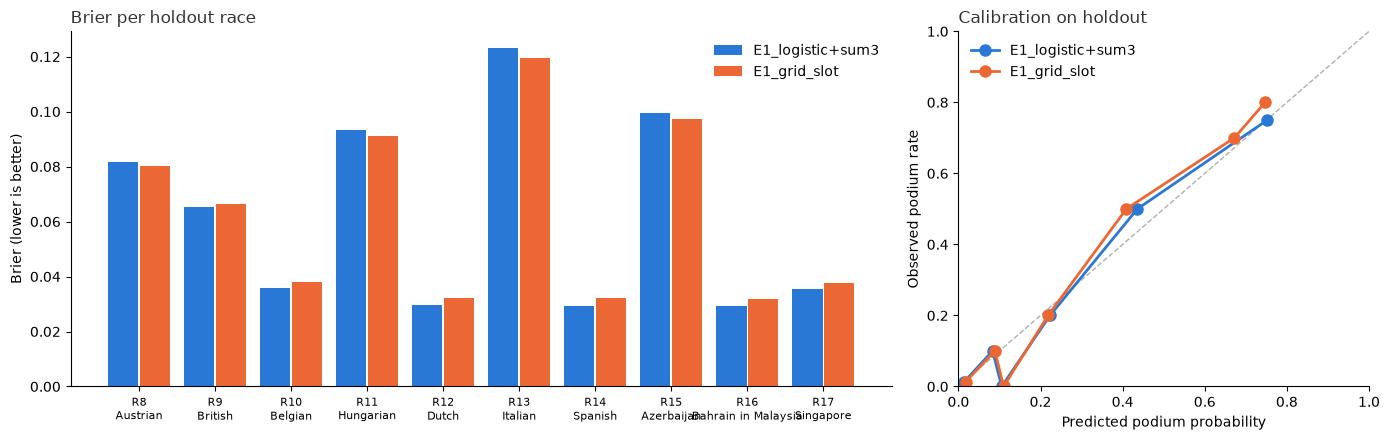

In [25]:
# ========================================
# PHASE 5 | STEP 4: Where It Fails (per race, by season, chaotic races) + Final Plots
# ========================================

race_labels = evalkit.label_chaotic_races(entries)

holdout_by_race = evalkit.per_race_breakdown(holdout_chosen, holdout_e1, race_labels)
print("📋 HOLDOUT PER RACE (Δ = chosen - E1, negative = chosen better)\n")
print(holdout_by_race[['season', 'round', 'race_name', 'brier_model', 'brier_base', 'diff', 'sum_p',
                       'podium_grid', 'not_classified', 'chaotic']].round(4).to_string(index=False))

# Dev + holdout together for season and chaos breakdowns
dev_by_name = {preds['model'].iloc[0]: preds for preds in phase4_candidates}
all_by_race = evalkit.per_race_breakdown(
    pd.concat([dev_by_name[CONFIG['chosen_model']], holdout_chosen], ignore_index=True),
    pd.concat([dev_predictions['E1_grid_slot'], holdout_e1], ignore_index=True),
    race_labels,
)
by_season = evalkit.breakdown_by(all_by_race, 'season')
by_chaos = evalkit.breakdown_by(all_by_race, 'chaotic')

print("\n📅 BY SEASON (dev + holdout)")
print(by_season.round(4).to_string(index=False))
print("\n🌪️ CHAOTIC RACES (podium finisher from P7 or lower)")
print(by_chaos.round(4).to_string(index=False))

print()
evalkit.plot_holdout_results(holdout_by_race, holdout_chosen, holdout_e1,
                             save_path=PROJECT_DIR / 'artifacts' / 'phase5_holdout.png')

In [26]:
# ========================================
# PHASE 5 | STEP 5: results.md + Decision Recorded
# ========================================

evalkit.write_results_note(
    path=PROJECT_DIR / 'results.md',
    lock=holdout_lock,
    passed=holdout_passed,
    holdout_results=holdout_results,
    holdout_improvement=holdout_improvement,
    dev_results=model_results[model_results['model'].isin(['E1_grid_slot', CONFIG['chosen_model']])],
    per_race=holdout_by_race,
    by_season=by_season,
    by_chaos=by_chaos,
    ablation=ablation,
    model_results=model_results,
    chosen_model=CONFIG['chosen_model'],
)

CONFIG['holdout_passed'] = holdout_passed
print(f"\n🏁 PHASE 5 DONE: decision recorded → {'model beats E1' if holdout_passed else 'grid-slot lookup is hard to beat'}")
print(f"   Phase 7 predict_race(): {'build it' if holdout_passed else 'skip (plan: only if Phase 5 shows a real lift)'}")

📝 Wrote results.md

🏁 PHASE 5 DONE: decision recorded → grid-slot lookup is hard to beat
   Phase 7 predict_race(): skip (plan: only if Phase 5 shows a real lift)


In [27]:
# ========================================
# PHASE 6 | STEP 1: Refresh Data (pull newly completed races)
# Weekend routine: run STEP 1 → STEP 2 after qualifying | run STEP 1 → STEP 3 after the race
# ========================================

CONFIG['forward_log'] = CONFIG['paths']['predictions'] / 'forward_log.parquet'

live_races, live_entries = data.refresh_entries(CONFIG['seasons'], CONFIG['paths']['raw'])
last = live_entries.iloc[-1]
print(f"\n✅ Latest completed race: {last['season']} R{last['round']} {last['race_name']}")

📊 COLLECTING RAW DATA (2022-2026)
   Source: Jolpica (Ergast-compatible), cached per race in data/raw

🏎️  Season 2022: 22 on calendar | 22 completed | results 22 | qualifying 22 ✅
🏎️  Season 2023: 22 on calendar | 22 completed | results 22 | qualifying 22 ✅
🏎️  Season 2024: 24 on calendar | 24 completed | results 24 | qualifying 24 ✅
🏎️  Season 2025: 24 on calendar | 24 completed | results 24 | qualifying 24 ✅
🏎️  Season 2026: 23 on calendar | 17 completed | results 17 | qualifying 17 ✅

✅ Collected: 109 races with results, 109 with qualifying
🌐 Live API calls this run: 0 (everything else from cache)

📊 BUILDING ENTRIES TABLE

✅ Results rows: 2,212
✅ Qualifying rows: 2,207

🔗 Merging on season, round, driver_id...
✅ Entries: 2,212 rows | 109 races
✅ Podium rate: 14.8%

🔧 APPLYING KNOWN DATE FIXES

   ✅ 2023 R21 quali_datetime_utc: 2023-11-17 08:00:00+00:00 → 2023-11-18 08:00:00+00:00
   ✅ 2023 R21 race_datetime_utc: 2023-11-19 06:00:00+00:00 → 2023-11-19 06:00:00+00:00
   ✅ 2024 R22 q

In [28]:
# ========================================
# PHASE 6 | STEP 2: Predict the Next Race (after qualifying, before the race starts)
# Frozen spec: E1 + chosen model refit on all completed races, logged once, never edited
# ========================================

# Known grid penalties / pit-lane starts announced before the race, e.g. {'max_verstappen': 20}, 0 = pit lane
GRID_OVERRIDES = {}

upcoming = data.fetch_upcoming_race(CONFIG['seasons'][-1], CONFIG['paths']['raw'], GRID_OVERRIDES)

if not upcoming.empty:
    forward_preds = [
        evalkit.predict_forward(models.GridSlotBaseline(), live_entries, upcoming),
        evalkit.predict_forward(models.E1PlusLogistic([], 'E1_logistic'), live_entries, upcoming, sum_to_three=True),
    ]
    assert forward_preds[1]['model'].iloc[0] == CONFIG['chosen_model'], "Forward test must use the Phase 4 choice"

    print()
    forward_log = evalkit.log_forward_predictions(forward_preds, CONFIG['forward_log'])

    field = forward_preds[0][['driver_code', 'grid', 'p']].merge(
        forward_preds[1][['driver_code', 'p']], on='driver_code', suffixes=('_e1', '_chosen'))
    print(f"\n📋 Full field ({len(field)} drivers)")
    print(field.rename(columns={'p_e1': 'E1', 'p_chosen': CONFIG['chosen_model']}).round(3).to_string(index=False))

🏎️  Next race: 2026 R18 United States Grand Prix (americas)
   Qualifying: 2026-10-24 21:00:00+00:00 | Race start: 2026-10-25 20:00:00+00:00
   ⏳ Qualifying not published yet, run again after the session


In [29]:
# ========================================
# PHASE 6 | STEP 3: Score Logged Races (after each race, run STEP 1 first)
# ========================================

if CONFIG['forward_log'].exists():
    forward_by_race, forward_results = evalkit.score_forward_log(
        CONFIG['forward_log'], live_entries, baseline='E1_grid_slot',
        n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])

    scored_races = 0 if forward_by_race.empty else len(forward_by_race)
    print(f"\n{'🏁 PHASE 6 DONE' if scored_races >= 3 else '⏳ PHASE 6 IN PROGRESS'}: "
          f"{scored_races} real race(s) logged and scored (plan: at least a few)")
else:
    print("⏳ No forward predictions logged yet, run STEP 2 after qualifying")

⏳ No forward predictions logged yet, run STEP 2 after qualifying


In [30]:
# ========================================
# PHASE 7A | STEP 1: Winner Target + Dev Backtests (W1, W1_logistic)
# Same construction as the podium model, target = official P1, scored on the same 55 dev races
# ========================================

winner_dev_table = evalkit.winner_view(dev_table)
print(f"✅ Winner view: {winner_dev_table.groupby(['season', 'round']).ngroups} races, exactly 1 winner each\n")

winner_predictions = {}
for model in [models.WinnerGridSlotBaseline(), models.E1PlusLogistic([], 'W1_logistic')]:
    winner_predictions[model.name] = evalkit.backtest(model, winner_dev_table, dev_races,
                                                      save_dir=CONFIG['paths']['predictions'])

# Each race rescaled to sum to 1 (one winner)
for name in list(winner_predictions):
    rescaled = evalkit.rescale_to_total(winner_predictions[name], total=1, suffix='sum1')
    winner_predictions[rescaled['model'].iloc[0]] = rescaled


✅ Winner view: 99 races, exactly 1 winner each

🏋️ BACKTEST: W1_grid_slot on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_W1_grid_slot.parquet
🏋️ BACKTEST: W1_logistic on 55 races (retrain every 1)
   💾 Saved 1,112 predictions → dev_W1_logistic.parquet


In [31]:
# ========================================
# PHASE 7A | STEP 2: Winner Results + Pre-committed Choice
# Rule: ship W1_logistic+sum1 unless its dev Brier is worse than W1 (no clean holdout for this target)
# ========================================

winner_results = evalkit.compare_models(list(winner_predictions.values()), baseline='W1_grid_slot',
                                        n_boot=CONFIG['n_boot'], seed=CONFIG['seed'])

print("\n🎯 Calibration: W1_logistic+sum1")
print(evalkit.calibration_table(winner_predictions['W1_logistic+sum1']).to_string(index=False))

print()
winner_model_name = evalkit.choose_winner_model(winner_results, baseline='W1_grid_slot', candidate='W1_logistic+sum1')
CONFIG['winner_model'] = winner_model_name

print(f"\n🏁 PHASE 7A DONE: winner model = {winner_model_name}")

📊 RESULTS (55 races, 95% intervals by race bootstrap)

   Model              Brier          [95% CI]  LogLoss          [95% CI]  Δ vs W1_grid_slot            [95% CI]      Σp per race
   W1_grid_slot      0.0305 [0.0258, 0.0352]   0.1062 [0.0905, 0.1243]            +0.0000 [+0.0000, +0.0000]  0.95 (0.92-0.97)
   W1_logistic       0.0300 [0.0247, 0.0355]   0.1050 [0.0876, 0.1249]            -0.0004 [-0.0011, +0.0003]  1.00 (0.99-1.01)
   W1_grid_slot+sum1  0.0302 [0.0254, 0.0353]   0.1060 [0.0899, 0.1243]            -0.0002 [-0.0005, +0.0001]  1.00 (1.00-1.00)
   W1_logistic+sum1  0.0300 [0.0247, 0.0355]   0.1050 [0.0876, 0.1249]            -0.0004 [-0.0011, +0.0003]  1.00 (1.00-1.00)

🎯 Calibration: W1_logistic+sum1
           bin  rows   mean_p  observed
(-0.001, 0.05]   943 0.009147  0.005302
   (0.05, 0.1]    32 0.088506  0.125000
    (0.1, 0.2]    45 0.136857  0.177778
    (0.2, 0.3]    37 0.212368  0.162162
    (0.3, 0.5]     1 0.494311  1.000000
    (0.5, 0.7]    54 0.537627  0.5

In [32]:
# ========================================
# PHASE 7B | STEP 1: Train Final Models on Every Completed Race + Export Parameters
# Podium = E1_logistic (+sum3), Winner = W1_logistic (+sum1), grid is the only input
# ========================================

assert CONFIG['winner_model'] == 'W1_logistic+sum1', "Export path below expects the logistic winner model"

final_models = {
    'podium': models.E1PlusLogistic([], 'E1_logistic').fit(entries),
    'winner': models.E1PlusLogistic([], 'W1_logistic').fit(evalkit.winner_view(entries)),
}
exported = {
    'podium': models.export_params(final_models['podium'], race_total=3),
    'winner': models.export_params(final_models['winner'], race_total=1),
}

last_race = entries.iloc[-1]
print(f"🏋️ Trained on {entries.groupby(['season', 'round']).ngroups} races ({len(entries):,} rows), "
      f"through {last_race['season']} R{last_race['round']} {last_race['race_name']}\n")

print("🔁 PARITY: exported parameters vs fitted models, every race")
for target in ['podium', 'winner']:
    table = entries if target == 'podium' else evalkit.winner_view(entries)
    worst = models.check_export_parity(final_models[target], exported[target], table)
    print(f"   {'✅' if worst < 1e-12 else '❌'} {target:7s} max |difference| = {worst:.1e}")
    assert worst < 1e-12

print("\n📋 Slot rates (before recalibration): podium | win")
for slot in [str(i) for i in range(1, 11)] + ['11+', 'pit']:
    print(f"   {slot:>4s}  {exported['podium']['slot_rates'][slot]:.3f} | {exported['winner']['slot_rates'][slot]:.3f}")

🏋️ Trained on 109 races (2,212 rows), through 2026 R17 Singapore Grand Prix

🔁 PARITY: exported parameters vs fitted models, every race
   ✅ podium  max |difference| = 0.0e+00
   ✅ winner  max |difference| = 0.0e+00

📋 Slot rates (before recalibration): podium | win
      1  0.752 | 0.534
      2  0.676 | 0.197
      3  0.441 | 0.088
      4  0.382 | 0.038
      5  0.214 | 0.013
      6  0.105 | 0.021
      7  0.088 | 0.013
      8  0.029 | 0.004
      9  0.029 | 0.013
     10  0.038 | 0.013
    11+  0.014 | 0.003
    pit  0.059 | 0.020


In [34]:
# ========================================
# PHASE 7B | STEP 2: Model Card + Save (pickles like V3, model.json for the web app)
# ========================================

model_card = {
    'project': 'F1 Predictor V4',
    'trained_at': pd.Timestamp.now(tz='UTC').isoformat(),
    'trained_through': f"{last_race['season']} R{last_race['round']} {last_race['race_name']}",
    'snapshot_hash': snapshot_hash,
    'training_races': int(entries.groupby(['season', 'round']).ngroups),
    'training_rows': len(entries),
    'python': platform.python_version(),
    'library_versions': library_versions,
    'inputs': "Starting grid only (slots 1-10, 11+ pooled, pit lane). Qualifying detail, driver form, "
              "team strength and circuit history did not improve dev Brier (Phase 3).",
    'podium': {
        'model': CONFIG['chosen_model'], 'baseline': 'E1_grid_slot',
        'dev': evalkit.summarize_result(model_results, CONFIG['chosen_model']),
        'holdout': evalkit.summarize_result(holdout_results, CONFIG['chosen_model']),
        'holdout_passed': holdout_passed,
        'note': "Did not beat the grid-slot baseline on the holdout: a recalibrated grid lookup.",
    },
    'winner': {
        'model': CONFIG['winner_model'], 'baseline': 'W1_grid_slot',
        'dev': evalkit.summarize_result(winner_results, CONFIG['winner_model']),
        'holdout': None,
        'note': "No clean holdout (it was opened once, for the podium model).",
    },
}

fixture_race = entries[(entries['season'] == last_race['season']) & (entries['round'] == last_race['round'])]
parity_fixture = {
    'race': f"{last_race['season']} R{last_race['round']} {last_race['race_name']}",
    'driver_code': fixture_race['driver_code'].tolist(),
    'grid': fixture_race['grid'].tolist(),
    'podium': models.predict_from_params(exported['podium'], fixture_race['grid']).tolist(),
    'winner': models.predict_from_params(exported['winner'], fixture_race['grid']).tolist(),
}

models.save_final_models(final_models, exported, model_card, CONFIG['paths']['models'], fixture=parity_fixture)

print(f"\n🏁 PHASE 7B DONE: trained models saved to artifacts/models/")

💾 SAVING FINAL MODELS

   ✅ podium_model.pkl         (E1_logistic)
   ✅ winner_model.pkl         (W1_logistic)
   ✅ model.json               (parameters + model card for the web app)
   ✅ parity_fixture.json      (one race, Python predictions to match in the browser)

🏁 PHASE 7B DONE: trained models saved to artifacts/models/


In [35]:
# ========================================
# PHASE 7D | STEP 1: Export Data for the Web App
# Re-run 7B STEP 2 first (the model card now includes the exact baseline Brier)
# ========================================

data.export_web_data(CONFIG['seasons'][-1], CONFIG['paths']['raw'], CONFIG['paths']['models'],
                     PROJECT_DIR / 'web' / 'public' / 'data')

print("\n🏁 PHASE 7D DATA DONE: run the app with `cd web && npm install && npm run dev`")

🌐 EXPORTING WEB DATA (2026)

   ✅ model.json
   ✅ parity_fixture.json
   ✅ season.json (23 races, 6 remaining, 22 drivers)

✅ Default grid: 2026 R17 Singapore Grand Prix qualifying

🏁 PHASE 7D DATA DONE: run the app with `cd web && npm install && npm run dev`
